# BRISC 2025 — Exploratory Data Analysis

This notebook performs exploratory data analysis of the BRISC 2025 brain MRI dataset before preprocessing and model training.

The analysis covers:

- classification class distribution
- train/test distributions
- imaging planes and MRI sequences
- image dimensions and aspect ratios
- image modes and intensity characteristics
- representative MRI samples
- segmentation mask characteristics
- tumor-region statistics
- leakage-aware dataset observations

The original BRISC dataset remains unchanged throughout this notebook.

Confirmed cross-split duplicates identified in `02_BRISC_Integrity_Checks.ipynb`
are loaded separately from `data/interim/` and used only for leakage-aware
analysis.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("EDA environment initialized.")
print("Current working directory:", Path.cwd())

EDA environment initialized.
Current working directory: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\notebooks


In [2]:
# --------------------------------------------------
# Project paths
# --------------------------------------------------

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_ROOT = PROJECT_ROOT / "data"
RAW_ROOT = DATA_ROOT / "raw"
INTERIM_ROOT = DATA_ROOT / "interim"
PROCESSED_ROOT = DATA_ROOT / "processed"

DATASET_ROOT = RAW_ROOT / "brisc2025"

CLASSIFICATION_ROOT = (
    DATASET_ROOT / "classification_task"
)

SEGMENTATION_ROOT = (
    DATASET_ROOT / "segmentation_task"
)

MANIFEST_PATH = DATASET_ROOT / "manifest.csv"

OUTPUT_ROOT = PROJECT_ROOT / "outputs"
FIGURES_ROOT = OUTPUT_ROOT / "figures"
TABLES_ROOT = OUTPUT_ROOT / "tables"


print("PROJECT ROOT")
print(PROJECT_ROOT)

print("\nDATASET ROOT")
print(DATASET_ROOT)

print("\nPATH CHECKS")
print("-" * 50)
print("Dataset exists       :", DATASET_ROOT.exists())
print("Manifest exists      :", MANIFEST_PATH.exists())
print("Classification exists:", CLASSIFICATION_ROOT.exists())
print("Segmentation exists  :", SEGMENTATION_ROOT.exists())
print("Interim folder exists:", INTERIM_ROOT.exists())
print("Figures folder exists:", FIGURES_ROOT.exists())
print("Tables folder exists :", TABLES_ROOT.exists())

PROJECT ROOT
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI

DATASET ROOT
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\raw\brisc2025

PATH CHECKS
--------------------------------------------------
Dataset exists       : True
Manifest exists      : True
Classification exists: True
Segmentation exists  : True
Interim folder exists: True
Figures folder exists: True
Tables folder exists : True


## 1. Dataset and Audit Metadata Loading

In [3]:
manifest_df = pd.read_csv(MANIFEST_PATH)

print("Manifest loaded successfully.")
print("Manifest shape:", manifest_df.shape)

print("\nColumns:")
for i, column in enumerate(manifest_df.columns, start=1):
    print(f"{i:>2}. {column}")

display(manifest_df.head())

Manifest loaded successfully.
Manifest shape: (15586, 16)

Columns:
 1. relative_path
 2. filename
 3. task
 4. split
 5. index
 6. tumor_code
 7. tumor_label
 8. plane_code
 9. plane_label
10. sequence
11. is_mask
12. linked_image
13. width
14. height
15. file_size_bytes
16. sha256


,relative_path,filename,task,split,index,tumor_code,tumor_label,plane_code,plane_label,sequence,is_mask,linked_image,width,height,file_size_bytes,sha256
0,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg,classification,test,1,gl,glioma,ax,axial,T1,False,NaN,512,512,25826,b513a83f68e486f45159b004d356782e78284014532151...
1,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg,classification,test,2,gl,glioma,ax,axial,T1,False,NaN,512,512,20982,5b4e4a0f482cb68955c340205d475f25c3a30718bd3b48...
2,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg,classification,test,3,gl,glioma,ax,axial,T1,False,NaN,512,512,13285,6fd1918b39e7a7f92fa5652d7802583f3251fed50a23ec...
3,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00004_gl_ax_t1.jpg,classification,test,4,gl,glioma,ax,axial,T1,False,NaN,512,512,26137,216b65a45d7effb4ebce1c9893f97d12449c9da777f818...
4,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00005_gl_ax_t1.jpg,classification,test,5,gl,glioma,ax,axial,T1,False,NaN,512,512,21709,c35734545021ab5a4f55fb87e08732e26fb16abe887927...


In [4]:
# --------------------------------------------------
# Classification records
# --------------------------------------------------

classification_df = manifest_df[
    manifest_df["task"] == "classification"
].copy()


# --------------------------------------------------
# Segmentation MRI records
# --------------------------------------------------

segmentation_mri_df = manifest_df[
    (manifest_df["task"] == "segmentation") &
    (manifest_df["is_mask"] == False)
].copy()


# --------------------------------------------------
# Segmentation mask records
# --------------------------------------------------

mask_df = manifest_df[
    (manifest_df["task"] == "segmentation") &
    (manifest_df["is_mask"] == True)
].copy()


print("DATAFRAME SUMMARY")
print("-" * 50)

print(
    "Classification MRI records:",
    len(classification_df)
)

print(
    "Segmentation MRI records:",
    len(segmentation_mri_df)
)

print(
    "Segmentation mask records:",
    len(mask_df)
)

DATAFRAME SUMMARY
--------------------------------------------------
Classification MRI records: 6000
Segmentation MRI records: 4793
Segmentation mask records: 4793


In [5]:
audit_files = {
    "train_exclusions":
        INTERIM_ROOT /
        "classification_train_exclusion_confirmed_duplicates.csv",

    "test_leakage":
        INTERIM_ROOT /
        "classification_test_leakage_reference.csv",

    "high_similarity_candidates":
        INTERIM_ROOT /
        "classification_high_similarity_unconfirmed_candidates.csv"
}


print("AUDIT FILE CHECK")
print("-" * 55)

for name, path in audit_files.items():
    print(f"{name:<30}: {path.exists()}")

AUDIT FILE CHECK
-------------------------------------------------------
train_exclusions              : True
test_leakage                  : True
high_similarity_candidates    : True


In [6]:
train_exclusion_df = pd.read_csv(
    audit_files["train_exclusions"]
)

test_leakage_df = pd.read_csv(
    audit_files["test_leakage"]
)

high_similarity_df = pd.read_csv(
    audit_files["high_similarity_candidates"]
)


print("AUDIT DATA LOADED")
print("-" * 50)

print(
    "Confirmed affected training images:",
    len(train_exclusion_df)
)

print(
    "Confirmed affected testing images:",
    len(test_leakage_df)
)

print(
    "Strong but unconfirmed candidate pairs:",
    len(high_similarity_df)
)

AUDIT DATA LOADED
--------------------------------------------------
Confirmed affected training images: 104
Confirmed affected testing images: 101
Strong but unconfirmed candidate pairs: 21


## 2. Classification Dataset — Class and Split Distribution

This section examines the distribution of the four classification labels in
the official BRISC training and testing splits.

The original BRISC split is analyzed first. Confirmed cross-split duplicate
records identified during the integrity audit are considered separately in
the subsequent leakage-aware analysis.

In [7]:
CLASS_ORDER = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]


overall_class_counts = (
    classification_df["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER)
)

train_class_counts = (
    classification_df[
        classification_df["split"] == "train"
    ]["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER)
)

test_class_counts = (
    classification_df[
        classification_df["split"] == "test"
    ]["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER)
)


class_distribution_df = pd.DataFrame({
    "train": train_class_counts,
    "test": test_class_counts,
    "total": overall_class_counts
})

class_distribution_df["train_percent"] = (
    100 *
    class_distribution_df["train"] /
    class_distribution_df["train"].sum()
)

class_distribution_df["test_percent"] = (
    100 *
    class_distribution_df["test"] /
    class_distribution_df["test"].sum()
)

class_distribution_df["overall_percent"] = (
    100 *
    class_distribution_df["total"] /
    class_distribution_df["total"].sum()
)


print("OFFICIAL CLASSIFICATION DISTRIBUTION")
print("-" * 60)

display(
    class_distribution_df.round(2)
)

OFFICIAL CLASSIFICATION DISTRIBUTION
------------------------------------------------------------


,train,test,total,train_percent,test_percent,overall_percent
tumor_label,,,,,,
glioma,1147,254,1401,22.94,25.4,23.35
meningioma,1329,306,1635,26.58,30.6,27.25
no_tumor,1067,140,1207,21.34,14.0,20.12
pituitary,1457,300,1757,29.14,30.0,29.28


In [8]:
print("CLASS BALANCE SUMMARY")
print("-" * 60)

print("Total classification images:", len(classification_df))

print(
    "Training images:",
    (classification_df["split"] == "train").sum()
)

print(
    "Testing images:",
    (classification_df["split"] == "test").sum()
)


overall_largest = overall_class_counts.idxmax()
overall_smallest = overall_class_counts.idxmin()

train_largest = train_class_counts.idxmax()
train_smallest = train_class_counts.idxmin()

test_largest = test_class_counts.idxmax()
test_smallest = test_class_counts.idxmin()


print("\nOVERALL")
print(
    "Largest class:",
    overall_largest,
    "-",
    overall_class_counts[overall_largest]
)

print(
    "Smallest class:",
    overall_smallest,
    "-",
    overall_class_counts[overall_smallest]
)

print(
    "Max/min ratio:",
    round(
        overall_class_counts.max() /
        overall_class_counts.min(),
        3
    )
)


print("\nTRAIN")
print(
    "Largest class:",
    train_largest,
    "-",
    train_class_counts[train_largest]
)

print(
    "Smallest class:",
    train_smallest,
    "-",
    train_class_counts[train_smallest]
)

print(
    "Max/min ratio:",
    round(
        train_class_counts.max() /
        train_class_counts.min(),
        3
    )
)


print("\nTEST")
print(
    "Largest class:",
    test_largest,
    "-",
    test_class_counts[test_largest]
)

print(
    "Smallest class:",
    test_smallest,
    "-",
    test_class_counts[test_smallest]
)

print(
    "Max/min ratio:",
    round(
        test_class_counts.max() /
        test_class_counts.min(),
        3
    )
)

CLASS BALANCE SUMMARY
------------------------------------------------------------
Total classification images: 6000
Training images: 5000
Testing images: 1000

OVERALL
Largest class: pituitary - 1757
Smallest class: no_tumor - 1207
Max/min ratio: 1.456

TRAIN
Largest class: pituitary - 1457
Smallest class: no_tumor - 1067
Max/min ratio: 1.366

TEST
Largest class: meningioma - 306
Smallest class: no_tumor - 140
Max/min ratio: 2.186


### 2.1 Overall Classification Class Distribution

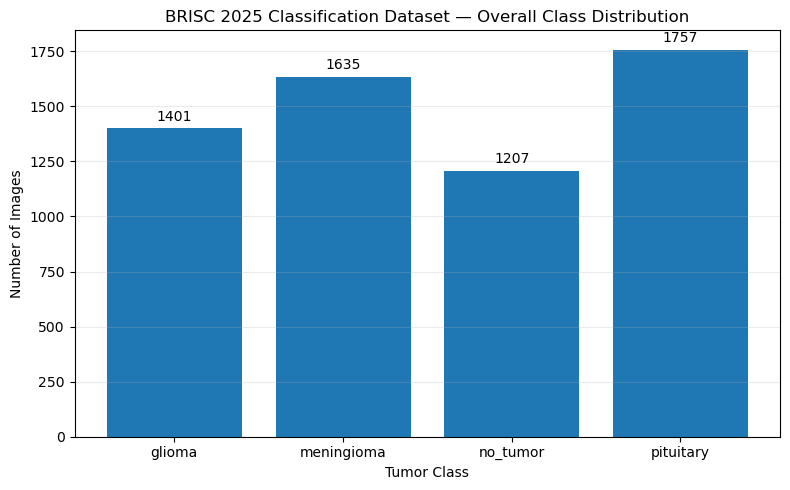

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\eda_classification_overall_class_distribution.png


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    overall_class_counts.index,
    overall_class_counts.values
)

ax.set_title(
    "BRISC 2025 Classification Dataset — Overall Class Distribution"
)

ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Images")

ax.grid(
    axis="y",
    alpha=0.25
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 20,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "eda_classification_overall_class_distribution.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

### 2.2 Official Train/Test Class Distribution

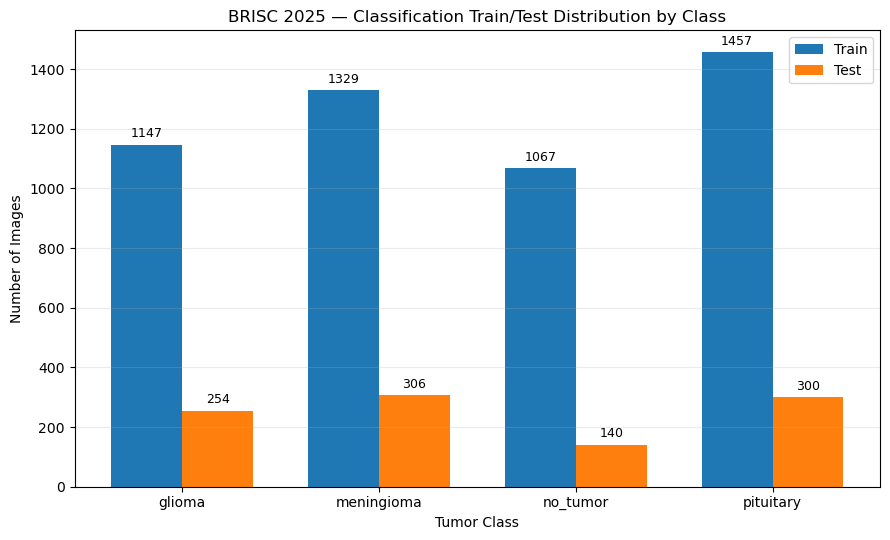

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\eda_classification_train_test_distribution.png


In [10]:
x = np.arange(len(CLASS_ORDER))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5))

train_bars = ax.bar(
    x - width / 2,
    train_class_counts.values,
    width,
    label="Train"
)

test_bars = ax.bar(
    x + width / 2,
    test_class_counts.values,
    width,
    label="Test"
)

ax.set_title(
    "BRISC 2025 — Classification Train/Test Distribution by Class"
)

ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Images")

ax.set_xticks(x)
ax.set_xticklabels(CLASS_ORDER)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)


for bars in [train_bars, test_bars]:
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 15,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=9
        )


plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "eda_classification_train_test_distribution.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

In [11]:
table_path = (
    TABLES_ROOT /
    "eda_classification_class_distribution.csv"
)

class_distribution_df.to_csv(
    table_path
)

print("Class-distribution table saved to:")
print(table_path)

Class-distribution table saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_classification_class_distribution.csv


### 2.3 Leakage-Aware Classification Distribution

The official BRISC classification test split contains confirmed cross-split
duplicates identified during the integrity audit.

This section separates confirmed contaminated test images from the remaining
test images without modifying the raw dataset. The purpose is to quantify how
the effective evaluation distribution differs from the published split.

In [12]:
# Confirmed contaminated test images by class
contaminated_test_counts = (
    test_leakage_df["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Official test counts
official_test_counts = (
    classification_df[
        classification_df["split"] == "test"
    ]["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Remaining non-confirmed-contaminated test images
remaining_test_counts = (
    official_test_counts - contaminated_test_counts
)

leakage_distribution_df = pd.DataFrame({
    "official_test": official_test_counts,
    "confirmed_contaminated": contaminated_test_counts,
    "remaining_test": remaining_test_counts
})

leakage_distribution_df["contamination_percent"] = (
    100 *
    leakage_distribution_df["confirmed_contaminated"] /
    leakage_distribution_df["official_test"]
)

leakage_distribution_df["remaining_percent"] = (
    100 *
    leakage_distribution_df["remaining_test"] /
    leakage_distribution_df["official_test"]
)

print("LEAKAGE-AWARE TEST DISTRIBUTION")
print("-" * 65)

display(
    leakage_distribution_df.round(2)
)

LEAKAGE-AWARE TEST DISTRIBUTION
-----------------------------------------------------------------


,official_test,confirmed_contaminated,remaining_test,contamination_percent,remaining_percent
tumor_label,,,,,
glioma,254,0,254,0.00,100.00
meningioma,306,96,210,31.37,68.63
no_tumor,140,0,140,0.00,100.00
pituitary,300,5,295,1.67,98.33


In [13]:
total_official_test = int(
    leakage_distribution_df["official_test"].sum()
)

total_contaminated = int(
    leakage_distribution_df[
        "confirmed_contaminated"
    ].sum()
)

total_remaining = int(
    leakage_distribution_df[
        "remaining_test"
    ].sum()
)


print("LEAKAGE-AWARE TEST SUMMARY")
print("-" * 60)

print("Official test images :", total_official_test)
print("Confirmed contaminated:", total_contaminated)
print("Remaining test images :", total_remaining)

print(
    "Overall contamination:",
    f"{100 * total_contaminated / total_official_test:.2f}%"
)

print(
    "Remaining proportion :",
    f"{100 * total_remaining / total_official_test:.2f}%"
)


print("\nREMAINING TEST CLASS BALANCE")
print("-" * 60)

print(
    "Largest remaining class:",
    remaining_test_counts.idxmax(),
    "-",
    remaining_test_counts.max()
)

print(
    "Smallest remaining class:",
    remaining_test_counts.idxmin(),
    "-",
    remaining_test_counts.min()
)

print(
    "Max/min ratio:",
    round(
        remaining_test_counts.max() /
        remaining_test_counts.min(),
        3
    )
)

LEAKAGE-AWARE TEST SUMMARY
------------------------------------------------------------
Official test images : 1000
Confirmed contaminated: 101
Remaining test images : 899
Overall contamination: 10.10%
Remaining proportion : 89.90%

REMAINING TEST CLASS BALANCE
------------------------------------------------------------
Largest remaining class: pituitary - 295
Smallest remaining class: no_tumor - 140
Max/min ratio: 2.107


### 2.4 Confirmed Test-Set Contamination by Class

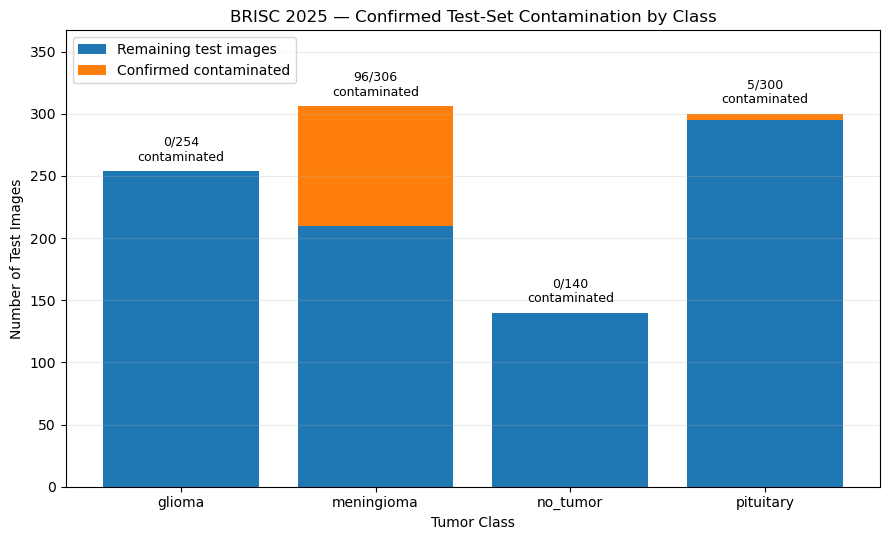

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\eda_classification_test_leakage_by_class.png


In [17]:
x = np.arange(len(CLASS_ORDER))

fig, ax = plt.subplots(figsize=(9, 5.5))

remaining_bars = ax.bar(
    x,
    remaining_test_counts.values,
    label="Remaining test images"
)

contaminated_bars = ax.bar(
    x,
    contaminated_test_counts.values,
    bottom=remaining_test_counts.values,
    label="Confirmed contaminated"
)

ax.set_title(
    "BRISC 2025 — Confirmed Test-Set Contamination by Class"
)

ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Test Images")

ax.set_xticks(x)
ax.set_xticklabels(CLASS_ORDER)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

ax.set_ylim(
    0,
    official_test_counts.max() * 1.20
)

for i, tumor_class in enumerate(CLASS_ORDER):

    remaining = int(
        remaining_test_counts[tumor_class]
    )

    contaminated = int(
        contaminated_test_counts[tumor_class]
    )

    official = int(
        official_test_counts[tumor_class]
    )

    ax.text(
        i,
        official + 6,
        f"{contaminated}/{official}\ncontaminated",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "eda_classification_test_leakage_by_class.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

In [15]:
table_path = (
    TABLES_ROOT /
    "eda_classification_test_leakage_distribution.csv"
)

leakage_distribution_df.to_csv(
    table_path
)

print("Leakage-aware distribution table saved to:")
print(table_path)

Leakage-aware distribution table saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_classification_test_leakage_distribution.csv


### 2.5 Training-Side Confirmed Duplicate Distribution

Confirmed cross-split duplication also affects a subset of images in the
official training split.

This section quantifies the number of affected training images by tumor class
and examines how their exclusion would change the effective training
distribution. The raw BRISC dataset is not modified.

In [18]:
confirmed_train_counts = (
    train_exclusion_df["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

official_train_counts = (
    classification_df[
        classification_df["split"] == "train"
    ]["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

remaining_train_counts = (
    official_train_counts - confirmed_train_counts
)

train_leakage_distribution_df = pd.DataFrame({
    "official_train": official_train_counts,
    "confirmed_duplicate_train": confirmed_train_counts,
    "remaining_train": remaining_train_counts
})

train_leakage_distribution_df[
    "affected_percent"
] = (
    100 *
    train_leakage_distribution_df[
        "confirmed_duplicate_train"
    ] /
    train_leakage_distribution_df[
        "official_train"
    ]
)

train_leakage_distribution_df[
    "remaining_percent"
] = (
    100 *
    train_leakage_distribution_df[
        "remaining_train"
    ] /
    train_leakage_distribution_df[
        "official_train"
    ]
)

print("TRAINING-SIDE CONFIRMED DUPLICATE DISTRIBUTION")
print("-" * 70)

display(
    train_leakage_distribution_df.round(2)
)

TRAINING-SIDE CONFIRMED DUPLICATE DISTRIBUTION
----------------------------------------------------------------------


,official_train,confirmed_duplicate_train,remaining_train,affected_percent,remaining_percent
tumor_label,,,,,
glioma,1147,0,1147,0.00,100.00
meningioma,1329,97,1232,7.30,92.70
no_tumor,1067,0,1067,0.00,100.00
pituitary,1457,7,1450,0.48,99.52


In [19]:
total_official_train = int(
    train_leakage_distribution_df[
        "official_train"
    ].sum()
)

total_affected_train = int(
    train_leakage_distribution_df[
        "confirmed_duplicate_train"
    ].sum()
)

total_remaining_train = int(
    train_leakage_distribution_df[
        "remaining_train"
    ].sum()
)

print("TRAINING-SIDE DUPLICATION SUMMARY")
print("-" * 60)

print(
    "Official training images :",
    total_official_train
)

print(
    "Confirmed affected images:",
    total_affected_train
)

print(
    "Remaining training images :",
    total_remaining_train
)

print(
    "Affected proportion       :",
    f"{100 * total_affected_train / total_official_train:.2f}%"
)

print(
    "Remaining proportion      :",
    f"{100 * total_remaining_train / total_official_train:.2f}%"
)


print("\nREMAINING TRAINING CLASS BALANCE")
print("-" * 60)

print(
    "Largest remaining class:",
    remaining_train_counts.idxmax(),
    "-",
    remaining_train_counts.max()
)

print(
    "Smallest remaining class:",
    remaining_train_counts.idxmin(),
    "-",
    remaining_train_counts.min()
)

print(
    "Max/min ratio:",
    round(
        remaining_train_counts.max() /
        remaining_train_counts.min(),
        3
    )
)

TRAINING-SIDE DUPLICATION SUMMARY
------------------------------------------------------------
Official training images : 5000
Confirmed affected images: 104
Remaining training images : 4896
Affected proportion       : 2.08%
Remaining proportion      : 97.92%

REMAINING TRAINING CLASS BALANCE
------------------------------------------------------------
Largest remaining class: pituitary - 1450
Smallest remaining class: no_tumor - 1067
Max/min ratio: 1.359


### 2.6 Confirmed Training-Side Duplicates by Class

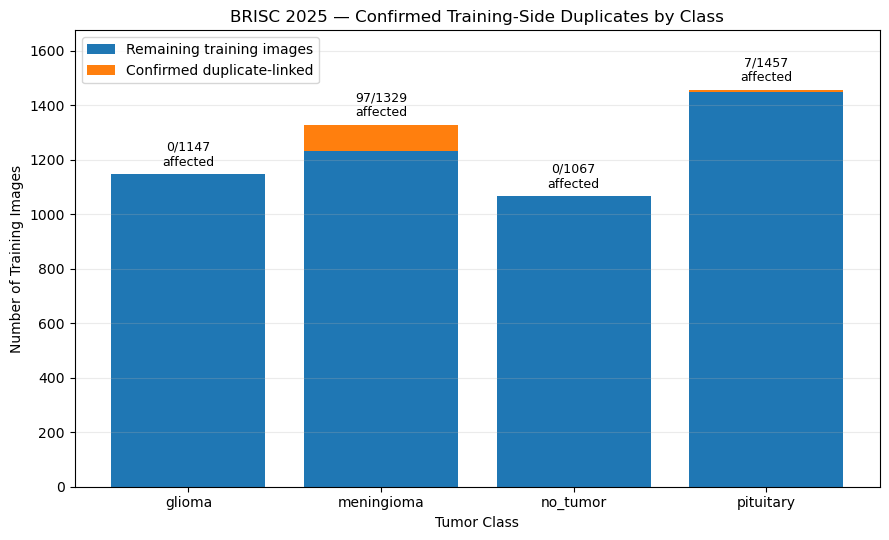

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\eda_classification_train_duplicates_by_class.png


In [20]:
x = np.arange(len(CLASS_ORDER))

fig, ax = plt.subplots(figsize=(9, 5.5))

remaining_bars = ax.bar(
    x,
    remaining_train_counts.values,
    label="Remaining training images"
)

affected_bars = ax.bar(
    x,
    confirmed_train_counts.values,
    bottom=remaining_train_counts.values,
    label="Confirmed duplicate-linked"
)

ax.set_title(
    "BRISC 2025 — Confirmed Training-Side Duplicates by Class"
)

ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Training Images")

ax.set_xticks(x)
ax.set_xticklabels(CLASS_ORDER)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

ax.set_ylim(
    0,
    official_train_counts.max() * 1.15
)

for i, tumor_class in enumerate(CLASS_ORDER):

    affected = int(
        confirmed_train_counts[tumor_class]
    )

    official = int(
        official_train_counts[tumor_class]
    )

    ax.text(
        i,
        official + 20,
        f"{affected}/{official}\naffected",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "eda_classification_train_duplicates_by_class.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

In [21]:
table_path = (
    TABLES_ROOT /
    "eda_classification_train_duplicate_distribution.csv"
)

train_leakage_distribution_df.to_csv(
    table_path
)

print("Training-side duplicate table saved to:")
print(table_path)

Training-side duplicate table saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_classification_train_duplicate_distribution.csv


## 3. MRI Acquisition Metadata

The BRISC manifest provides acquisition-related metadata including imaging
plane and MRI sequence.

This section examines the distribution of these metadata variables across the
classification dataset and determines whether the confirmed cross-split
duplication is associated with particular acquisition categories.

In [22]:
print("MRI ACQUISITION METADATA")
print("-" * 60)

print("\nUnique imaging planes:")
print(
    sorted(
        classification_df["plane_label"]
        .dropna()
        .unique()
        .tolist()
    )
)

print("\nPlane counts:")
print(
    classification_df["plane_label"]
    .value_counts()
)

print("\nUnique MRI sequences:")
print(
    sorted(
        classification_df["sequence"]
        .dropna()
        .unique()
        .tolist()
    )
)

print("\nSequence counts:")
print(
    classification_df["sequence"]
    .value_counts()
)

print("\nPlane × Sequence:")
display(
    pd.crosstab(
        classification_df["plane_label"],
        classification_df["sequence"],
        margins=True
    )
)

MRI ACQUISITION METADATA
------------------------------------------------------------

Unique imaging planes:
['axial', 'coronal', 'sagittal']

Plane counts:
plane_label
sagittal    2026
axial       1993
coronal     1981
Name: count, dtype: int64

Unique MRI sequences:
['T1']

Sequence counts:
sequence
T1    6000
Name: count, dtype: int64

Plane × Sequence:


sequence,T1,All
plane_label,,
axial,1993,1993
coronal,1981,1981
sagittal,2026,2026
All,6000,6000


In [23]:
plane_split_table = pd.crosstab(
    classification_df["plane_label"],
    classification_df["split"]
)

plane_split_table["total"] = (
    plane_split_table.sum(axis=1)
)

plane_split_table["overall_percent"] = (
    100 *
    plane_split_table["total"] /
    plane_split_table["total"].sum()
)

print("CLASSIFICATION IMAGES BY MRI PLANE")
print("-" * 60)

display(
    plane_split_table.round(2)
)

CLASSIFICATION IMAGES BY MRI PLANE
------------------------------------------------------------


split,test,train,total,overall_percent
plane_label,,,,
axial,398,1595,1993,33.22
coronal,305,1676,1981,33.02
sagittal,297,1729,2026,33.77


In [26]:
# Load confirmed cross-split duplicate records created in Notebook 2

confirmed_test_df = pd.read_csv(
    INTERIM_ROOT /
    "classification_confirmed_leaked_test_images.csv"
)

confirmed_train_df = pd.read_csv(
    INTERIM_ROOT /
    "classification_confirmed_duplicate_train_images.csv"
)

print("Confirmed contaminated test records:", len(confirmed_test_df))
print("Confirmed duplicate-linked train records:", len(confirmed_train_df))


# ------------------------------------------------------------
# Count confirmed affected images by MRI plane
# ------------------------------------------------------------

confirmed_test_planes = (
    confirmed_test_df["plane_label"]
    .value_counts()
)

confirmed_train_planes = (
    confirmed_train_df["plane_label"]
    .value_counts()
)


# Official train/test plane distributions

official_test_planes = (
    classification_df[
        classification_df["split"] == "test"
    ]["plane_label"]
    .value_counts()
)

official_train_planes = (
    classification_df[
        classification_df["split"] == "train"
    ]["plane_label"]
    .value_counts()
)


all_planes = sorted(
    classification_df["plane_label"]
    .dropna()
    .unique()
)


plane_leakage_df = pd.DataFrame(index=all_planes)

plane_leakage_df["official_train"] = (
    official_train_planes
    .reindex(all_planes, fill_value=0)
)

plane_leakage_df["affected_train"] = (
    confirmed_train_planes
    .reindex(all_planes, fill_value=0)
)

plane_leakage_df["official_test"] = (
    official_test_planes
    .reindex(all_planes, fill_value=0)
)

plane_leakage_df["affected_test"] = (
    confirmed_test_planes
    .reindex(all_planes, fill_value=0)
)


plane_leakage_df["train_affected_percent"] = (
    100 *
    plane_leakage_df["affected_train"] /
    plane_leakage_df["official_train"]
)

plane_leakage_df["test_contamination_percent"] = (
    100 *
    plane_leakage_df["affected_test"] /
    plane_leakage_df["official_test"]
)


print("\nCONFIRMED DUPLICATION BY MRI PLANE")
print("-" * 70)

display(
    plane_leakage_df.round(2)
)

Confirmed contaminated test records: 101
Confirmed duplicate-linked train records: 104

CONFIRMED DUPLICATION BY MRI PLANE
----------------------------------------------------------------------


,official_train,affected_train,official_test,affected_test,train_affected_percent,test_contamination_percent
axial,1595,64,398,63,4.01,15.83
coronal,1676,24,305,22,1.43,7.21
sagittal,1729,16,297,16,0.93,5.39


### Confirmed Cross-Split Duplication by MRI Plane

The confirmed cross-split duplication was evaluated according to MRI acquisition plane to determine whether contamination was uniformly distributed across axial, coronal, and sagittal images.

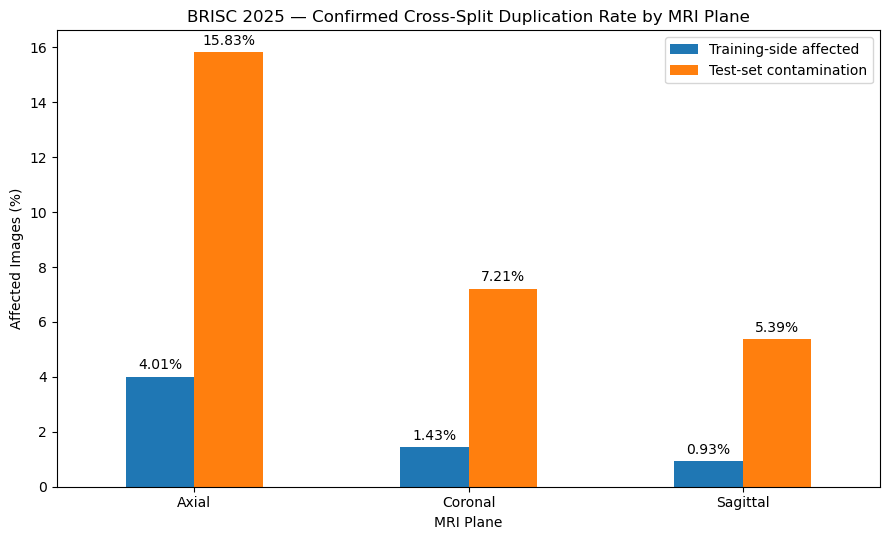

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\eda_classification_duplication_rate_by_plane.png


In [27]:
import matplotlib.pyplot as plt

plot_df = plane_leakage_df[
    [
        "train_affected_percent",
        "test_contamination_percent"
    ]
].copy()

ax = plot_df.plot(
    kind="bar",
    figsize=(9, 5.5)
)

ax.set_title(
    "BRISC 2025 — Confirmed Cross-Split Duplication Rate by MRI Plane"
)

ax.set_xlabel("MRI Plane")
ax.set_ylabel("Affected Images (%)")

ax.set_xticklabels(
    [label.capitalize() for label in plot_df.index],
    rotation=0
)

ax.legend(
    [
        "Training-side affected",
        "Test-set contamination"
    ]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "eda_classification_duplication_rate_by_plane.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

In [28]:
table_path = (
    TABLES_ROOT /
    "eda_classification_duplication_by_plane.csv"
)

plane_leakage_df.to_csv(
    table_path,
    index_label="plane_label"
)

print("MRI-plane duplication table saved to:")
print(table_path)

MRI-plane duplication table saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_classification_duplication_by_plane.csv


#### Interpretation

Although the classification dataset is approximately balanced across axial, coronal, and sagittal MRI planes, confirmed cross-split duplication is not uniformly distributed across these planes.

The axial subset shows the highest contamination, with 63 of 398 official test images affected (15.83%), compared with 22 of 305 coronal images (7.21%) and 16 of 297 sagittal images (5.39%).

A similar pattern is observed on the training side, where 4.01% of axial images are associated with confirmed cross-split duplicates, compared with 1.43% of coronal images and 0.93% of sagittal images.

Thus, the duplication problem is disproportionately concentrated in axial MRI images rather than simply reflecting the overall plane distribution of the dataset.

### Statistical Association Between MRI Plane and Test-Set Contamination

A chi-square test of independence was performed to determine whether confirmed cross-split contamination in the classification test set was associated with MRI acquisition plane.

The analysis compares contaminated and uncontaminated test images across axial, coronal, and sagittal planes. Cramér's V is additionally calculated to quantify the strength of the association.

In [29]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# Build contingency table directly from the previously verified plane table
plane_stats_df = plane_leakage_df[
    ["official_test", "affected_test"]
].copy()

plane_stats_df["unaffected_test"] = (
    plane_stats_df["official_test"] -
    plane_stats_df["affected_test"]
)

contingency_table = plane_stats_df[
    ["affected_test", "unaffected_test"]
]

print("TEST-SET CONTAMINATION × MRI PLANE")
print("-" * 65)

display(contingency_table)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=["expected_affected", "expected_unaffected"]
)

# Cramer's V
n = contingency_table.to_numpy().sum()
r, c = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

# Pearson residuals
observed = contingency_table.to_numpy()
pearson_residuals = (
    observed - expected
) / np.sqrt(expected)

residual_df = pd.DataFrame(
    pearson_residuals,
    index=contingency_table.index,
    columns=[
        "affected_residual",
        "unaffected_residual"
    ]
)

print("\nCHI-SQUARE TEST")
print("-" * 65)
print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("p-value:", f"{p_value:.10g}")
print("Cramer's V:", round(cramers_v, 4))

print("\nEXPECTED COUNTS")
print("-" * 65)
display(expected_df.round(2))

print("\nPEARSON RESIDUALS")
print("-" * 65)
display(residual_df.round(3))

TEST-SET CONTAMINATION × MRI PLANE
-----------------------------------------------------------------


,affected_test,unaffected_test
axial,63,335
coronal,22,283
sagittal,16,281



CHI-SQUARE TEST
-----------------------------------------------------------------
Chi-square statistic: 24.4518
Degrees of freedom: 2
p-value: 4.901814506e-06
Cramer's V: 0.1564

EXPECTED COUNTS
-----------------------------------------------------------------


,expected_affected,expected_unaffected
axial,40.2,357.8
coronal,30.8,274.2
sagittal,30.0,267.0



PEARSON RESIDUALS
-----------------------------------------------------------------


,affected_residual,unaffected_residual
axial,3.596,-1.205
coronal,-1.586,0.532
sagittal,-2.556,0.857


### Statistical Interpretation

A chi-square test of independence found a statistically significant association between MRI acquisition plane and confirmed cross-split contamination in the classification test set:

**χ²(2) = 24.452, p = 4.90 × 10⁻⁶.**

Therefore, the null hypothesis that MRI plane and contamination status are independent is rejected.

Cramér's V was **0.156**, indicating a relatively small but meaningful association between MRI plane and contamination.

Inspection of the Pearson residuals showed that the axial plane contributed most strongly to the association. Axial images had substantially more contaminated samples than expected under independence (**residual = +3.596**), whereas sagittal images had fewer contaminated samples than expected (**residual = −2.556**). Coronal images were also below expectation, although less strongly (**residual = −1.586**).

These statistical findings support the descriptive analysis: cross-split duplication is disproportionately concentrated in axial MRI images rather than being uniformly distributed across acquisition planes.

In [30]:
# Save MRI-plane contamination statistical analysis

plane_chi_square_summary = pd.DataFrame({
    "chi_square": [chi2],
    "degrees_of_freedom": [dof],
    "p_value": [p_value],
    "cramers_v": [cramers_v]
})

summary_path = (
    TABLES_ROOT /
    "eda_classification_plane_contamination_chi_square.csv"
)

residual_path = (
    TABLES_ROOT /
    "eda_classification_plane_contamination_residuals.csv"
)

plane_chi_square_summary.to_csv(
    summary_path,
    index=False
)

residual_df.to_csv(
    residual_path,
    index_label="plane_label"
)

print("Statistical summary saved to:")
print(summary_path)

print("\nPearson residual table saved to:")
print(residual_path)

Statistical summary saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_classification_plane_contamination_chi_square.csv

Pearson residual table saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_classification_plane_contamination_residuals.csv


# 3. Segmentation Dataset Exploratory Data Analysis

This section examines the BRISC 2025 segmentation subset, including image-mask composition, tumor-class distribution, MRI-plane distribution, and characteristics of the segmentation masks.

Unlike the classification analysis, segmentation EDA must consider both the MRI images and their corresponding binary tumor masks.

In [31]:
# Separate segmentation MRI images and segmentation masks

segmentation_df = manifest_df[
    manifest_df["task"] == "segmentation"
].copy()

segmentation_mri_df = segmentation_df[
    segmentation_df["is_mask"] == False
].copy()

segmentation_mask_df = segmentation_df[
    segmentation_df["is_mask"] == True
].copy()

print("SEGMENTATION DATASET SUMMARY")
print("-" * 60)

print("Total manifest records :", len(segmentation_df))
print("MRI image records      :", len(segmentation_mri_df))
print("Mask records           :", len(segmentation_mask_df))

print("\nMRI IMAGES BY SPLIT")
print("-" * 60)
print(segmentation_mri_df["split"].value_counts())

print("\nMASKS BY SPLIT")
print("-" * 60)
print(segmentation_mask_df["split"].value_counts())

SEGMENTATION DATASET SUMMARY
------------------------------------------------------------
Total manifest records : 9586
MRI image records      : 4793
Mask records           : 4793

MRI IMAGES BY SPLIT
------------------------------------------------------------
split
train    3933
test      860
Name: count, dtype: int64

MASKS BY SPLIT
------------------------------------------------------------
split
train    3933
test      860
Name: count, dtype: int64


## 3.1 Segmentation Tumor-Class Distribution

The segmentation dataset contains one MRI image and one corresponding tumor mask for each case. To avoid double-counting, class-distribution analysis is performed using only the MRI-image records.

In [32]:
# Segmentation MRI distribution by tumor class and split

seg_class_counts = pd.crosstab(
    segmentation_mri_df["tumor_label"],
    segmentation_mri_df["split"]
)

# Ensure consistent column order
for split_name in ["train", "test"]:
    if split_name not in seg_class_counts.columns:
        seg_class_counts[split_name] = 0

seg_class_counts = seg_class_counts[["train", "test"]]

seg_class_counts["total"] = (
    seg_class_counts["train"] +
    seg_class_counts["test"]
)

seg_class_counts["train_percent"] = (
    100 * seg_class_counts["train"] /
    seg_class_counts["train"].sum()
)

seg_class_counts["test_percent"] = (
    100 * seg_class_counts["test"] /
    seg_class_counts["test"].sum()
)

seg_class_counts["overall_percent"] = (
    100 * seg_class_counts["total"] /
    seg_class_counts["total"].sum()
)

print("SEGMENTATION MRI CLASS DISTRIBUTION")
print("-" * 65)

display(seg_class_counts.round(2))

SEGMENTATION MRI CLASS DISTRIBUTION
-----------------------------------------------------------------


split,train,test,total,train_percent,test_percent,overall_percent
tumor_label,,,,,,
glioma,1147,254,1401,29.16,29.53,29.23
meningioma,1329,306,1635,33.79,35.58,34.11
pituitary,1457,300,1757,37.05,34.88,36.66


In [33]:
# Segmentation class-balance summary

overall_seg_counts = seg_class_counts["total"]
train_seg_counts = seg_class_counts["train"]
test_seg_counts = seg_class_counts["test"]

print("SEGMENTATION CLASS BALANCE SUMMARY")
print("-" * 60)

print("Total segmentation cases:", len(segmentation_mri_df))
print("Training cases:", len(
    segmentation_mri_df[
        segmentation_mri_df["split"] == "train"
    ]
))
print("Testing cases:", len(
    segmentation_mri_df[
        segmentation_mri_df["split"] == "test"
    ]
))

print("\nOVERALL")
print(
    "Largest class:",
    overall_seg_counts.idxmax(),
    "-",
    overall_seg_counts.max()
)
print(
    "Smallest class:",
    overall_seg_counts.idxmin(),
    "-",
    overall_seg_counts.min()
)
print(
    "Max/min ratio:",
    round(
        overall_seg_counts.max() /
        overall_seg_counts.min(),
        3
    )
)

print("\nTRAIN")
print(
    "Largest class:",
    train_seg_counts.idxmax(),
    "-",
    train_seg_counts.max()
)
print(
    "Smallest class:",
    train_seg_counts.idxmin(),
    "-",
    train_seg_counts.min()
)
print(
    "Max/min ratio:",
    round(
        train_seg_counts.max() /
        train_seg_counts.min(),
        3
    )
)

print("\nTEST")
print(
    "Largest class:",
    test_seg_counts.idxmax(),
    "-",
    test_seg_counts.max()
)
print(
    "Smallest class:",
    test_seg_counts.idxmin(),
    "-",
    test_seg_counts.min()
)
print(
    "Max/min ratio:",
    round(
        test_seg_counts.max() /
        test_seg_counts.min(),
        3
    )
)

SEGMENTATION CLASS BALANCE SUMMARY
------------------------------------------------------------
Total segmentation cases: 4793
Training cases: 3933
Testing cases: 860

OVERALL
Largest class: pituitary - 1757
Smallest class: glioma - 1401
Max/min ratio: 1.254

TRAIN
Largest class: pituitary - 1457
Smallest class: glioma - 1147
Max/min ratio: 1.27

TEST
Largest class: meningioma - 306
Smallest class: glioma - 254
Max/min ratio: 1.205


## 3.2 Segmentation MRI Plane Distribution

The distribution of segmentation cases across axial, coronal, and sagittal MRI planes is examined to determine whether particular acquisition orientations are disproportionately represented.

In [34]:
# Segmentation MRI distribution by imaging plane

seg_plane_counts = pd.crosstab(
    segmentation_mri_df["plane_label"],
    segmentation_mri_df["split"]
)

for split_name in ["train", "test"]:
    if split_name not in seg_plane_counts.columns:
        seg_plane_counts[split_name] = 0

seg_plane_counts = seg_plane_counts[["train", "test"]]

seg_plane_counts["total"] = (
    seg_plane_counts["train"] +
    seg_plane_counts["test"]
)

seg_plane_counts["overall_percent"] = (
    100 *
    seg_plane_counts["total"] /
    seg_plane_counts["total"].sum()
)

seg_plane_counts["train_percent"] = (
    100 *
    seg_plane_counts["train"] /
    seg_plane_counts["train"].sum()
)

seg_plane_counts["test_percent"] = (
    100 *
    seg_plane_counts["test"] /
    seg_plane_counts["test"].sum()
)

print("SEGMENTATION MRI DISTRIBUTION BY PLANE")
print("-" * 65)

display(seg_plane_counts.round(2))

SEGMENTATION MRI DISTRIBUTION BY PLANE
-----------------------------------------------------------------


split,train,test,total,overall_percent,train_percent,test_percent
plane_label,,,,,,
axial,1243,346,1589,33.15,31.60,40.23
coronal,1366,257,1623,33.86,34.73,29.88
sagittal,1324,257,1581,32.99,33.66,29.88


In [35]:
# Tumor class × MRI plane distribution

seg_class_plane_table = pd.crosstab(
    segmentation_mri_df["tumor_label"],
    segmentation_mri_df["plane_label"],
    margins=True
)

print("SEGMENTATION CLASS × MRI PLANE")
print("-" * 65)

display(seg_class_plane_table)

SEGMENTATION CLASS × MRI PLANE
-----------------------------------------------------------------


plane_label,axial,coronal,sagittal,All
tumor_label,,,,
glioma,479,511,411,1401
meningioma,560,512,563,1635
pituitary,550,600,607,1757
All,1589,1623,1581,4793


# 4. Segmentation Mask Characteristics

This section examines the pixel-level properties of the segmentation masks, including mask encoding, tumor foreground area, and the distribution of annotated tumor sizes across classes, MRI planes, and dataset splits.

In [36]:
import numpy as np
from PIL import Image
from pathlib import Path

observed_mask_values = set()
non_standard_masks = []

print("Scanning segmentation mask pixel values...")

for _, row in segmentation_mask_df.iterrows():

    mask_path = (
        DATASET_ROOT /
        Path(row["relative_path"])
    )

    with Image.open(mask_path) as img:
        mask_array = np.array(img)

    unique_values = np.unique(mask_array)

    observed_mask_values.update(
        unique_values.tolist()
    )

    # Common binary encodings are {0, 1} or {0, 255}
    if not set(unique_values.tolist()).issubset(
        {0, 1, 255}
    ):
        non_standard_masks.append(
            {
                "filename": row["filename"],
                "unique_values": unique_values.tolist()
            }
        )

print("\nMASK PIXEL-VALUE SUMMARY")
print("-" * 60)

print(
    "Unique pixel values observed across dataset:",
    sorted(observed_mask_values)
)

print(
    "Masks checked:",
    len(segmentation_mask_df)
)

print(
    "Masks with values outside {0, 1, 255}:",
    len(non_standard_masks)
)

if non_standard_masks:
    print("\nFirst few non-standard masks:")
    for item in non_standard_masks[:10]:
        print(item)
else:
    print(
        "\nMask encoding status: "
        "STANDARD BINARY ENCODING CONFIRMED"
    )

Scanning segmentation mask pixel values...

MASK PIXEL-VALUE SUMMARY
------------------------------------------------------------
Unique pixel values observed across dataset: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255]
Masks checked: 4793
Masks with values outside {0, 1, 255}: 4793

First few non-standard masks:
{'filename': 'brisc2025_test_00001_gl_ax_t1.png', 'unique_values': [0, 1, 2, 3, 4, 5, 7, 248, 249, 250, 251, 252, 253, 254, 255]}
{'filename': 'brisc2025_test_00002_gl_ax_t1.png', 'unique_values': [0, 1, 2, 3, 4, 5, 6, 249, 250, 251, 252, 253, 254, 255]}
{'filename': 'brisc2025_test_00003_gl_ax_t1.png', 'unique_values': [0, 1, 2, 3, 4, 5, 6, 7, 248, 249, 250, 251, 252, 253, 254, 255]}
{'filename': 'brisc2025_test_00004_gl_ax_t1.png', 'unique_values': [0, 1, 2, 3, 4, 5, 6, 7, 249, 250, 251, 252, 253, 254, 255]}
{'filename': 'brisc2025_test_00005_gl_ax_t1.png', 'unique_values': [0, 1, 2, 3, 4, 5, 6, 248, 250, 251, 252, 253, 254, 255]}
{'fi

## 4.1 Mask Encoding Verification

The raw segmentation masks are not encoded using strictly binary
pixel values. Instead, their values are concentrated near 0 and 255,
with no observed mid-range intensities.

This section quantifies the mask intensity distribution and verifies
that threshold-based binarization is appropriate before calculating
tumor-region statistics.

In [37]:
import numpy as np
from PIL import Image
from pathlib import Path

pixel_value_counts = np.zeros(256, dtype=np.int64)

masks_with_midrange_values = 0
masks_with_only_dark_values = 0
masks_with_only_bright_values = 0

for _, row in segmentation_mask_df.iterrows():

    mask_path = DATASET_ROOT / Path(row["relative_path"])

    with Image.open(mask_path) as img:
        arr = np.array(img)

    # Count every grayscale intensity
    pixel_value_counts += np.bincount(
        arr.ravel(),
        minlength=256
    )

    unique_vals = np.unique(arr)

    # Values away from both near-black and near-white ranges
    if np.any((unique_vals > 10) & (unique_vals < 246)):
        masks_with_midrange_values += 1

    if np.all(unique_vals <= 10):
        masks_with_only_dark_values += 1

    if np.all(unique_vals >= 246):
        masks_with_only_bright_values += 1


used_values = np.where(pixel_value_counts > 0)[0]

print("MASK INTENSITY VERIFICATION")
print("-" * 60)

print("Observed values:")
print(used_values.tolist())

print(
    "\nMasks containing values from 11-245:",
    masks_with_midrange_values
)

print(
    "Masks containing only near-black pixels:",
    masks_with_only_dark_values
)

print(
    "Masks containing only near-white pixels:",
    masks_with_only_bright_values
)

print("\nPIXEL COUNTS BY INTENSITY")
print("-" * 60)

for value in used_values:
    print(
        f"{value:3d}: "
        f"{pixel_value_counts[value]:,}"
    )

MASK INTENSITY VERIFICATION
------------------------------------------------------------
Observed values:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255]

Masks containing values from 11-245: 0
Masks containing only near-black pixels: 0
Masks containing only near-white pixels: 0

PIXEL COUNTS BY INTENSITY
------------------------------------------------------------
  0: 1,200,811,122
  1: 1,056,504
  2: 631,720
  3: 316,052
  4: 116,433
  5: 49,648
  6: 10,036
  7: 5,197
  8: 118
  9: 7
 10: 1
246: 11
247: 131
248: 4,342
249: 8,981
250: 45,463
251: 106,840
252: 285,175
253: 573,722
254: 961,182
255: 17,818,262


### Interpretation

The segmentation masks exhibit a strongly bimodal grayscale encoding.

Background pixels occupy the intensity range 0–10, whereas annotated
tumor pixels occupy the range 246–255. No pixel intensities were
observed between 11 and 245 across all 4,793 masks.

Therefore, the masks represent effectively binary segmentation maps
with minor edge-intensity variation, likely introduced during mask
generation or image encoding. A threshold of 128 can consequently be
used to obtain binary tumor masks without ambiguity.

Approximately 1.62% of all mask pixels belong to the foreground tumor
region, while approximately 98.38% correspond to background. This
indicates substantial pixel-level class imbalance, which should be
considered during segmentation-model training and metric selection.

No completely empty or completely foreground-filled masks were found.

## 4.2 Visual MRI–Mask Verification

A small sample of segmentation MRI images and their corresponding masks
is visualized to verify spatial alignment and confirm the interpretation
of the near-binary mask encoding.

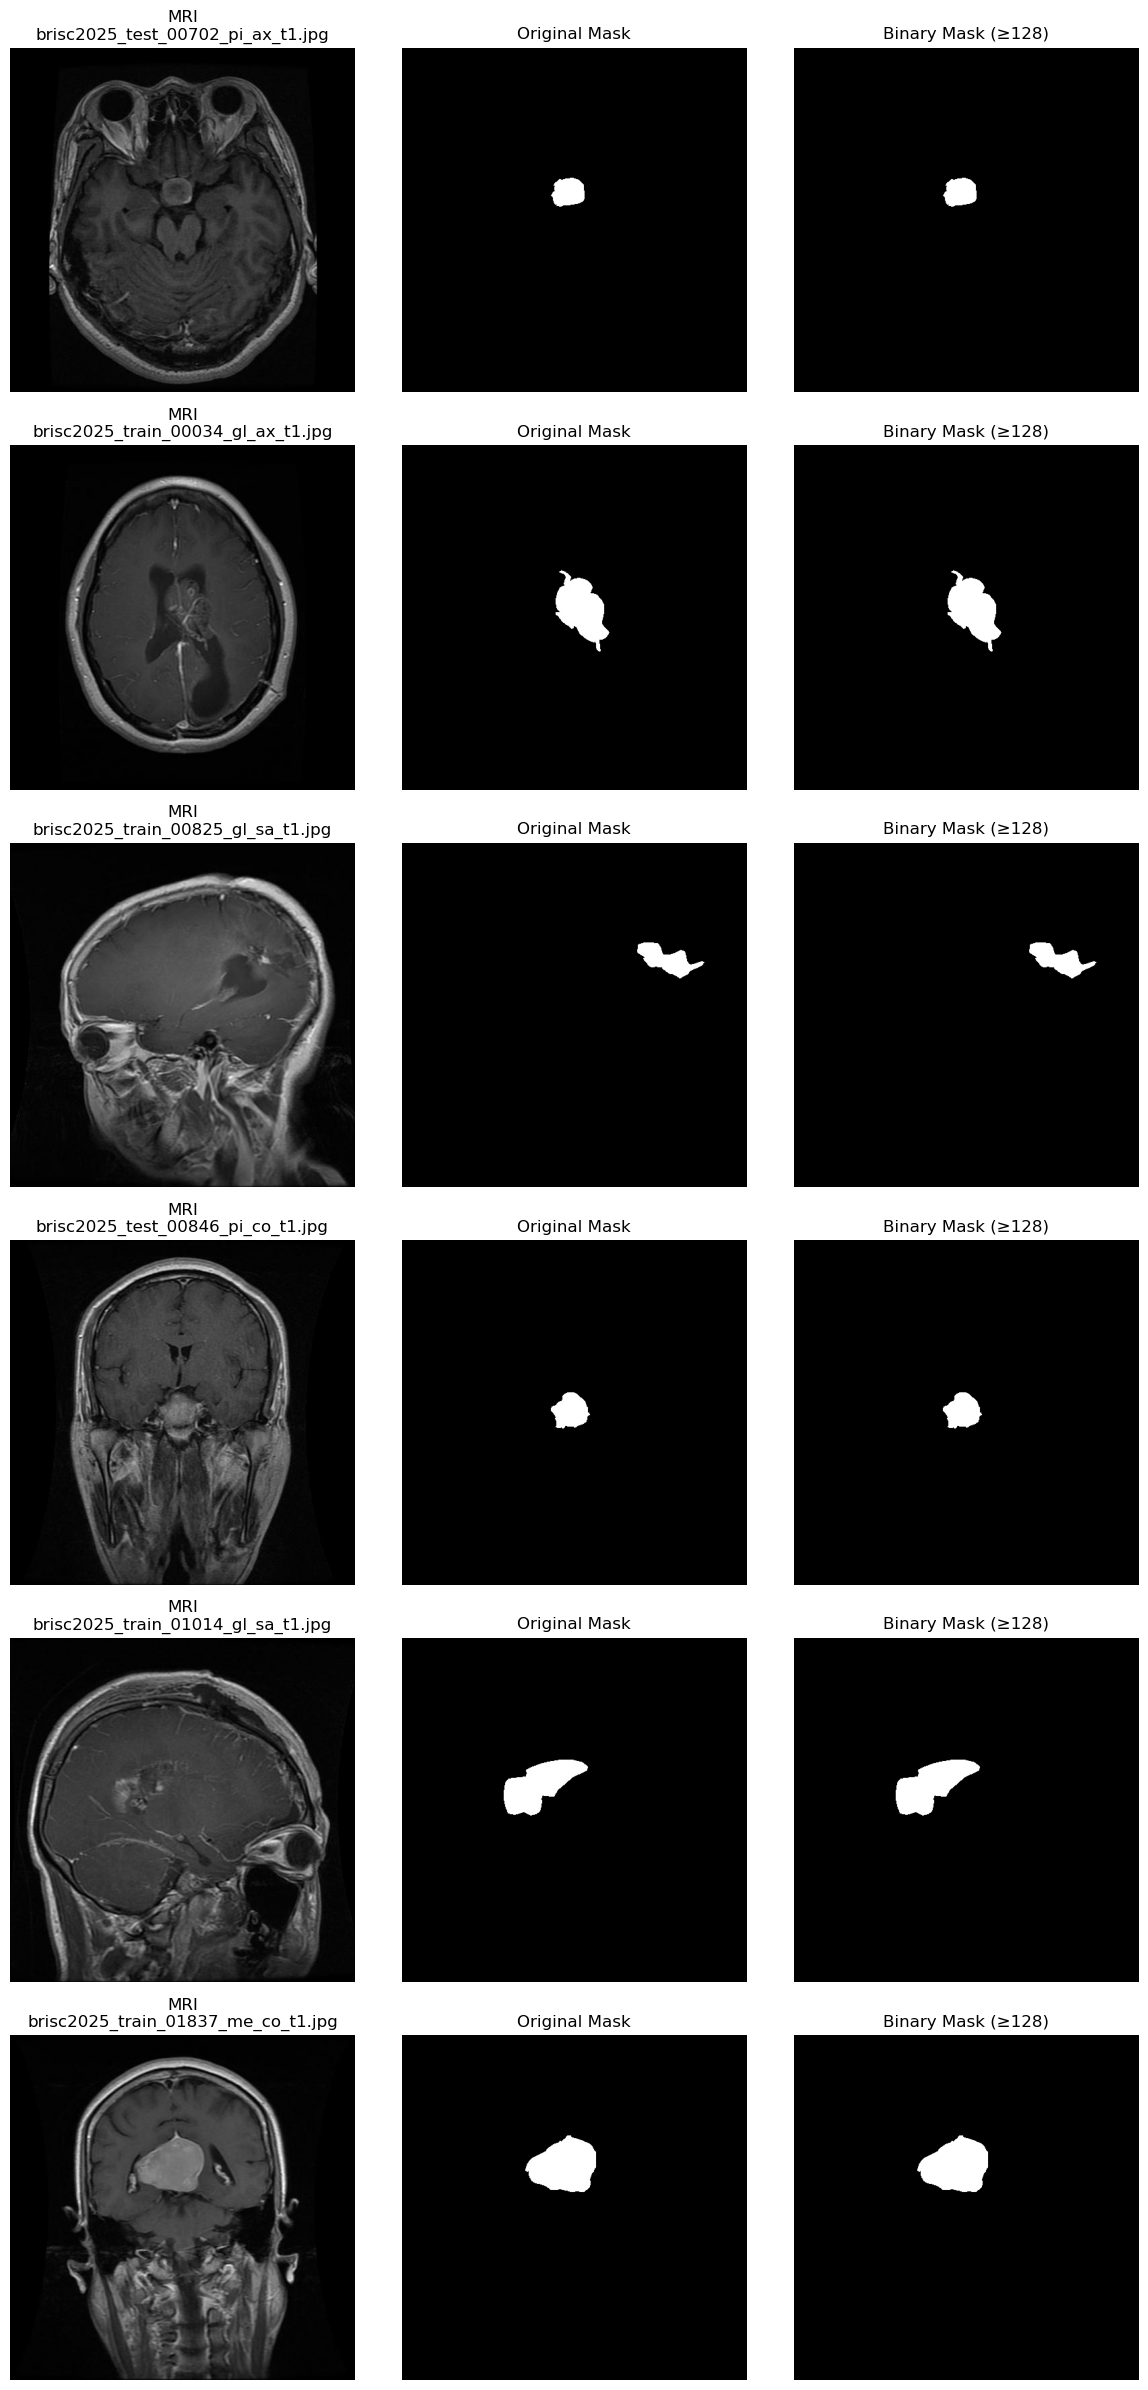

In [38]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path

# Select reproducible examples
sample_masks = segmentation_mask_df.sample(
    n=6,
    random_state=42
)

fig, axes = plt.subplots(
    len(sample_masks),
    3,
    figsize=(12, 4 * len(sample_masks))
)

for row_idx, (_, mask_row) in enumerate(sample_masks.iterrows()):

    # Linked MRI image
    image_path = (
        DATASET_ROOT /
        Path(mask_row["linked_image"])
    )

    # Corresponding mask
    mask_path = (
        DATASET_ROOT /
        Path(mask_row["relative_path"])
    )

    with Image.open(image_path) as img:
        image_arr = np.array(img)

    with Image.open(mask_path) as mask:
        mask_arr = np.array(mask)

    binary_mask = mask_arr >= 128

    # MRI
    axes[row_idx, 0].imshow(
        image_arr,
        cmap="gray"
    )
    axes[row_idx, 0].set_title(
        f"MRI\n{Path(image_path).name}"
    )

    # Raw mask
    axes[row_idx, 1].imshow(
        mask_arr,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row_idx, 1].set_title("Original Mask")

    # Thresholded mask
    axes[row_idx, 2].imshow(
        binary_mask,
        cmap="gray"
    )
    axes[row_idx, 2].set_title("Binary Mask (≥128)")

    for ax in axes[row_idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Visual Verification Result

Visual inspection of representative MRI–mask pairs confirmed that the
segmentation masks are spatially consistent with their corresponding MRI
images.

The original grayscale masks and masks binarized using an intensity
threshold of 128 produced effectively identical segmentation regions in
the inspected examples. No obvious spatial displacement, orientation
mismatch, or threshold-induced loss of annotated regions was observed.

Combined with the previously verified image–mask filename pairing and
dimension consistency, these results support the use of a threshold of
128 for subsequent quantitative segmentation-mask analysis.

## 4.3 Tumor Region Size Analysis

The binary segmentation masks are used to quantify the relative size of
the annotated tumor region in each MRI slice.

Because physical pixel-spacing information is not available in the
dataset manifest, tumor size is expressed using foreground pixel count
and foreground percentage of the total image area rather than physical
units such as mm².

In [39]:
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path

tumor_area_records = []

print("Computing tumor-region statistics...")

for _, row in segmentation_mask_df.iterrows():

    mask_path = DATASET_ROOT / Path(row["relative_path"])

    with Image.open(mask_path) as mask:
        mask_arr = np.array(mask)

    binary_mask = mask_arr >= 128

    foreground_pixels = int(binary_mask.sum())
    total_pixels = int(binary_mask.size)

    foreground_percent = (
        100 * foreground_pixels / total_pixels
    )

    tumor_area_records.append({
        "filename": row["filename"],
        "split": row["split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "width": mask_arr.shape[1],
        "height": mask_arr.shape[0],
        "foreground_pixels": foreground_pixels,
        "total_pixels": total_pixels,
        "tumor_percent": foreground_percent
    })


tumor_area_df = pd.DataFrame(tumor_area_records)

print("Done.")
print("Masks analysed:", len(tumor_area_df))

display(tumor_area_df.head())

print("\nTUMOR REGION SUMMARY")
print("-" * 60)

print(
    tumor_area_df[
        ["foreground_pixels", "tumor_percent"]
    ].describe().round(3)
)

Computing tumor-region statistics...
Done.
Masks analysed: 4793


,filename,split,tumor_label,plane_label,width,height,foreground_pixels,total_pixels,tumor_percent
0,brisc2025_test_00001_gl_ax_t1.png,test,glioma,axial,512,512,1151,262144,0.439072
1,brisc2025_test_00002_gl_ax_t1.png,test,glioma,axial,512,512,2181,262144,0.831985
2,brisc2025_test_00003_gl_ax_t1.png,test,glioma,axial,512,512,5789,262144,2.208328
3,brisc2025_test_00004_gl_ax_t1.png,test,glioma,axial,512,512,3989,262144,1.521683
4,brisc2025_test_00005_gl_ax_t1.png,test,glioma,axial,512,512,1192,262144,0.454712



TUMOR REGION SUMMARY
------------------------------------------------------------
       foreground_pixels  tumor_percent
count           4793.000       4793.000
mean            4131.882          1.694
std             3748.903          1.497
min               23.000          0.009
25%             1806.000          0.710
50%             3199.000          1.255
75%             5239.000          2.144
max            73320.000         17.347


### Tumor Region Size Summary

Tumor-region area was quantified from all 4,793 segmentation masks after
binarization at an intensity threshold of 128.

All masks contained a non-zero foreground region. Tumor coverage showed
substantial variation across MRI slices, with a median annotated area of
1.255% of the image and an interquartile range from approximately 0.710%
to 2.144%.

The mean tumor coverage (1.694%) exceeded the median, suggesting a
right-skewed distribution caused by a smaller number of relatively large
tumor regions. The observed maximum coverage was 17.347%.

Because the dataset contains images with different native resolutions,
normalized tumor percentage is used as the primary measure for
cross-image comparisons rather than raw foreground-pixel count.

In [40]:
# Tumor-region statistics by tumor class

def grouped_tumor_summary(df, group_columns):

    grouped = df.groupby(group_columns)["tumor_percent"]

    summary = grouped.agg(
        cases="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )

    summary["q1"] = grouped.quantile(0.25)
    summary["q3"] = grouped.quantile(0.75)

    return summary[
        [
            "cases",
            "mean",
            "median",
            "std",
            "q1",
            "q3",
            "minimum",
            "maximum"
        ]
    ]


class_tumor_summary = grouped_tumor_summary(
    tumor_area_df,
    ["tumor_label"]
)

print("TUMOR REGION SIZE BY CLASS")
print("-" * 70)

display(class_tumor_summary.round(3))


# Also check train/test separately

class_split_tumor_summary = grouped_tumor_summary(
    tumor_area_df,
    ["tumor_label", "split"]
)

print("\nTUMOR REGION SIZE BY CLASS AND SPLIT")
print("-" * 70)

display(class_split_tumor_summary.round(3))

TUMOR REGION SIZE BY CLASS
----------------------------------------------------------------------


,cases,mean,median,std,q1,q3,minimum,maximum
tumor_label,,,,,,,,
glioma,1401,1.867,1.521,1.481,0.816,2.456,0.053,9.770
meningioma,1635,2.245,1.736,1.828,0.995,2.976,0.009,17.347
pituitary,1757,1.042,0.864,0.727,0.544,1.354,0.058,6.487



TUMOR REGION SIZE BY CLASS AND SPLIT
----------------------------------------------------------------------


cases   mean  median    std     q1     q3  minimum  maximum
tumor_label split                                                             
glioma      test     254  1.941   1.282  1.665  0.792  2.711    0.095    9.770
            train   1147  1.850   1.556  1.437  0.826  2.415    0.053    8.895
meningioma  test     306  2.870   2.066  2.364  1.182  3.784    0.208   15.450
            train   1329  2.102   1.670  1.649  0.977  2.792    0.009   17.347
pituitary   test     300  0.891   0.698  0.637  0.479  1.216    0.082    4.876
            train   1457  1.073   0.904  0.740  0.563  1.382    0.058    6.487

### Tumor Region Size by Tumor Class

Normalized tumor-region coverage differs substantially across the three
segmentation classes.

Meningioma images show the largest annotated tumor regions, with a mean
coverage of 2.245% and a median of 1.736%. Glioma occupies an intermediate
position, with a mean of 1.867% and median of 1.521%, while pituitary
tumors have the smallest relative mask areas, with a mean of 1.042% and
median of 0.864%.

The distributions are positively skewed, particularly for meningioma,
whose annotated regions range up to 17.347% of the image area.

Comparison of the official training and testing subsets also indicates
class-dependent differences in tumor-region size. Meningioma test cases
contain noticeably larger masks than training cases, whereas pituitary
test cases tend to contain somewhat smaller masks. Glioma shows similar
mean coverage between the two splits but greater dispersion within the
test subset.

These differences indicate that segmentation difficulty may vary across
both tumor class and dataset split and should therefore be considered
when interpreting future segmentation performance.

C:\Users\HP\AppData\Local\Temp\ipykernel_6588\1346204303.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


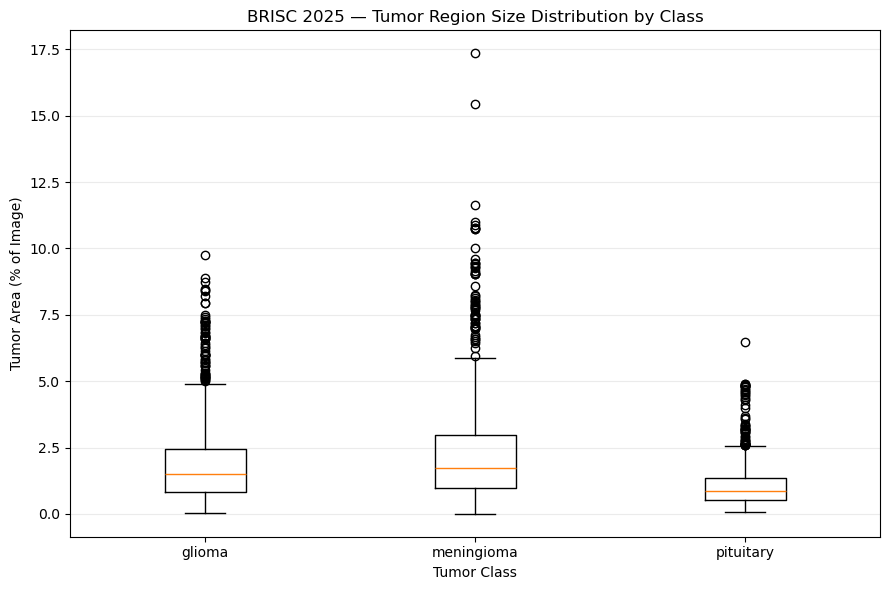

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\eda_segmentation_tumor_area_by_class.png


In [41]:
import matplotlib.pyplot as plt

class_order = ["glioma", "meningioma", "pituitary"]

# Prepare data for boxplot
class_data = [
    tumor_area_df.loc[
        tumor_area_df["tumor_label"] == label,
        "tumor_percent"
    ].values
    for label in class_order
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    class_data,
    labels=class_order,
    showfliers=True
)

ax.set_title(
    "BRISC 2025 — Tumor Region Size Distribution by Class"
)
ax.set_xlabel("Tumor Class")
ax.set_ylabel("Tumor Area (% of Image)")

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "eda_segmentation_tumor_area_by_class.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

### Interpretation

Tumor-region coverage exhibits substantial class-dependent variation and
strong positive skewness.

Meningioma cases generally contain the largest annotated tumor regions and
also show the greatest dispersion, including several comparatively large
tumor masks. Glioma cases occupy an intermediate range, while pituitary
tumors are typically smaller and show a more compact distribution.

The presence of numerous upper-tail observations indicates that tumor area
is not normally distributed. These observations are retained because they
represent potentially valid large tumor regions rather than being treated
automatically as erroneous outliers.

Consequently, subsequent comparisons of tumor-region size are performed
using distribution-aware and non-parametric statistical methods.

## 4.6 Tumor-Region Size by Class and Dataset Split

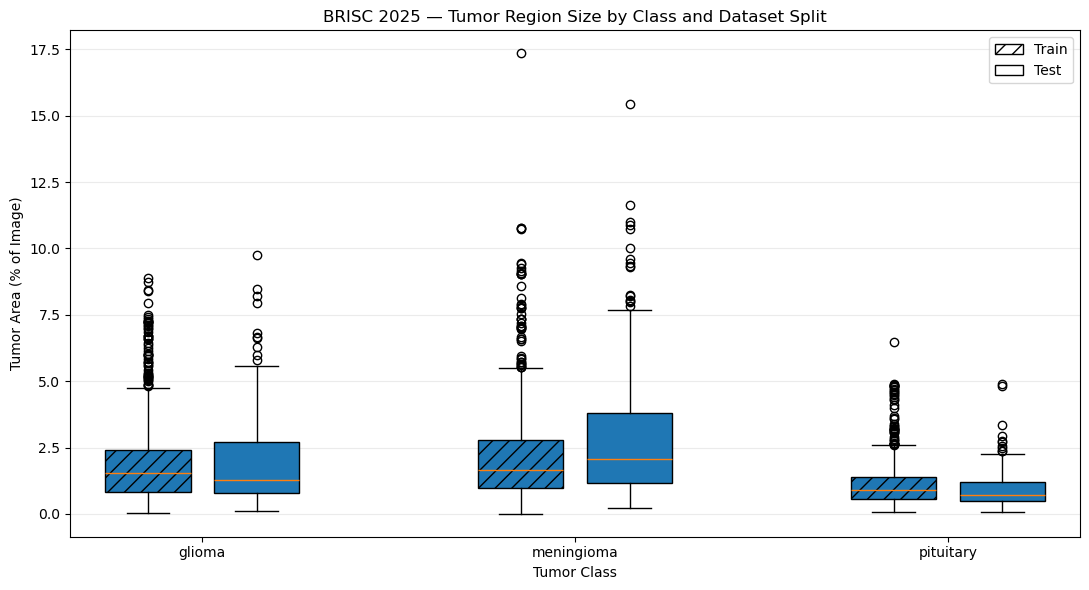

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\eda_segmentation_tumor_area_train_test.png


In [42]:
import matplotlib.pyplot as plt
import numpy as np

class_order = ["glioma", "meningioma", "pituitary"]

positions = []
plot_data = []
tick_positions = []

current_position = 1

for label in class_order:
    
    train_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "train")
    ]["tumor_percent"].values

    test_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "test")
    ]["tumor_percent"].values

    plot_data.extend([train_values, test_values])

    positions.extend([
        current_position,
        current_position + 0.7
    ])

    tick_positions.append(
        current_position + 0.35
    )

    current_position += 2.4


fig, ax = plt.subplots(figsize=(11, 6))

bp = ax.boxplot(
    plot_data,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showfliers=True
)

# Alternate hatch patterns instead of relying only on colour
for i, box in enumerate(bp["boxes"]):
    if i % 2 == 0:
        box.set_hatch("//")
    else:
        box.set_hatch("")

ax.set_xticks(tick_positions)
ax.set_xticklabels(class_order)

ax.set_xlabel("Tumor Class")
ax.set_ylabel("Tumor Area (% of Image)")

ax.set_title(
    "BRISC 2025 — Tumor Region Size by Class and Dataset Split"
)

ax.grid(axis="y", alpha=0.25)

# Legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch="//",
        label="Train"
    ),
    Patch(
        facecolor="white",
        edgecolor="black",
        label="Test"
    )
]

ax.legend(handles=legend_elements)

plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "eda_segmentation_tumor_area_train_test.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

## 4.7 Statistical Comparison of Tumor-Region Size Between Train and Test Splits

In [43]:
from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np

class_order = ["glioma", "meningioma", "pituitary"]

results = []

for label in class_order:

    train_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "train")
    ]["tumor_percent"].dropna()

    test_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "test")
    ]["tumor_percent"].dropna()

    u_stat, p_value = mannwhitneyu(
        train_values,
        test_values,
        alternative="two-sided"
    )

    # Rank-biserial correlation effect size
    n1 = len(train_values)
    n2 = len(test_values)

    rank_biserial = (
        1 - (2 * u_stat) / (n1 * n2)
    )

    results.append({
        "tumor_label": label,
        "train_n": n1,
        "test_n": n2,
        "train_median": train_values.median(),
        "test_median": test_values.median(),
        "U_statistic": u_stat,
        "p_value": p_value,
        "rank_biserial_effect": rank_biserial
    })


tumor_area_mwu_df = pd.DataFrame(results)

print("MANN-WHITNEY U TEST — TRAIN VS TEST")
print("-" * 70)

display(
    tumor_area_mwu_df.round({
        "train_median": 4,
        "test_median": 4,
        "U_statistic": 2,
        "p_value": 8,
        "rank_biserial_effect": 4
    })
)

MANN-WHITNEY U TEST — TRAIN VS TEST
----------------------------------------------------------------------


,tumor_label,train_n,test_n,train_median,test_median,U_statistic,p_value,rank_biserial_effect
0,glioma,1147,254,1.5560,1.2821,147091.5,8.074362e-01,-0.0098
1,meningioma,1329,306,1.6705,2.0665,165500.5,3.700000e-07,0.1861
2,pituitary,1457,300,0.9037,0.6981,255350.0,4.250000e-06,-0.1684


In [44]:
alpha = 0.05

print("\nINTERPRETATION")
print("-" * 70)

for _, row in tumor_area_mwu_df.iterrows():

    label = row["tumor_label"]
    p = row["p_value"]
    effect = abs(row["rank_biserial_effect"])

    if effect < 0.1:
        effect_label = "negligible"
    elif effect < 0.3:
        effect_label = "small"
    elif effect < 0.5:
        effect_label = "moderate"
    else:
        effect_label = "large"

    significance = (
        "statistically significant"
        if p < alpha
        else "not statistically significant"
    )

    print(
        f"{label}: {significance} "
        f"(p={p:.6g}), "
        f"{effect_label} effect "
        f"(|r_rb|={effect:.4f})"
    )


INTERPRETATION
----------------------------------------------------------------------
glioma: not statistically significant (p=0.807436), negligible effect (|r_rb|=0.0098)
meningioma: statistically significant (p=3.74718e-07), small effect (|r_rb|=0.1861)
pituitary: statistically significant (p=4.25185e-06), small effect (|r_rb|=0.1684)


### 4.8 Multiple-Comparison Correction

Because train/test tumor-region distributions were compared independently across
three tumor classes, Holm-adjusted p-values are computed to control the
family-wise error rate.

In [46]:
import numpy as np

# Raw p-values from the Mann–Whitney U tests
raw_p_values = tumor_area_mwu_df["p_value"].to_numpy()
m = len(raw_p_values)

# Sort p-values from smallest to largest
order = np.argsort(raw_p_values)
sorted_p = raw_p_values[order]

# Holm adjustment
holm_sorted = np.empty(m, dtype=float)

running_max = 0.0

for i, p in enumerate(sorted_p):
    adjusted = (m - i) * p
    running_max = max(running_max, adjusted)
    holm_sorted[i] = min(running_max, 1.0)

# Restore original class order
holm_adjusted = np.empty(m, dtype=float)
holm_adjusted[order] = holm_sorted

tumor_area_mwu_df["holm_adjusted_p"] = holm_adjusted
tumor_area_mwu_df["significant_after_holm"] = (
    tumor_area_mwu_df["holm_adjusted_p"] < 0.05
)

print("HOLM MULTIPLE-COMPARISON CORRECTION")
print("-" * 70)

display(
    tumor_area_mwu_df[
        [
            "tumor_label",
            "p_value",
            "holm_adjusted_p",
            "significant_after_holm",
            "rank_biserial_effect"
        ]
    ].round({
        "p_value": 10,
        "holm_adjusted_p": 10,
        "rank_biserial_effect": 4
    })
)

HOLM MULTIPLE-COMPARISON CORRECTION
----------------------------------------------------------------------


,tumor_label,p_value,holm_adjusted_p,significant_after_holm,rank_biserial_effect
0,glioma,8.074362e-01,0.807436,False,-0.0098
1,meningioma,3.747000e-07,0.000001,True,0.1861
2,pituitary,4.251800e-06,0.000009,True,-0.1684


### Interpretation — Multiple-Comparison Correction

Because tumor-region distributions were compared separately for glioma, meningioma, and pituitary cases, Holm correction was applied to control the family-wise error rate across the three Mann–Whitney U tests.

The corrected analysis preserved the original conclusions:

- **Glioma:** no statistically significant difference between training and testing tumor-area distributions.
- **Meningioma:** a statistically significant train–test difference remained after Holm correction, although the rank-biserial effect size was small.
- **Pituitary:** a statistically significant train–test difference also remained after Holm correction, with a small effect size.

For meningioma, the testing set showed a higher median tumor-area percentage than the training set, whereas the pituitary testing set showed a lower median tumor-area percentage than the training set.

Therefore, the segmentation train and test subsets are not perfectly distribution-matched with respect to tumor-region size for all tumor classes. However, the observed differences for the statistically significant classes have small effect sizes and should be interpreted as modest distributional shifts rather than severe dataset imbalance.

In [47]:
stats_path = (
    TABLES_ROOT /
    "eda_segmentation_tumor_area_train_test_statistics.csv"
)

tumor_area_mwu_df.to_csv(stats_path, index=False)

print("Tumor-area train/test statistical results saved to:")
print(stats_path)

Tumor-area train/test statistical results saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_segmentation_tumor_area_train_test_statistics.csv


# 5. Final EDA Summary and Modelling Implications

The exploratory data analysis of the BRISC 2025 dataset was completed for both the classification and segmentation tasks, with particular attention to class balance, MRI acquisition characteristics, train/test duplication, segmentation-mask structure, and tumor-region statistics.

## 5.1 Classification Dataset

The classification dataset contains **6,000 MRI images**, comprising **5,000 training images** and **1,000 testing images** across four classes: glioma, meningioma, no-tumor, and pituitary.

The official dataset is moderately balanced overall, although the test subset is less balanced than the training subset.

A major finding from the integrity analysis was **confirmed cross-split image duplication**. A total of **101 unique test images (10.10% of the official test set)** have confirmed duplicate image content represented in the training split.

The contamination is strongly class-dependent:

- **Meningioma:** 96 / 306 test images (31.37%)
- **Pituitary:** 5 / 300 test images (1.67%)
- **Glioma:** 0 / 254 test images
- **No-tumor:** 0 / 140 test images

The corresponding duplicate-linked training set contains **104 unique training images**, representing **2.08% of the official training set**.

Duplication is also associated with MRI acquisition plane. Test-set contamination rates were:

- **Axial:** 63 / 398 (15.83%)
- **Coronal:** 22 / 305 (7.21%)
- **Sagittal:** 16 / 297 (5.39%)

A chi-square test confirmed that contamination status and MRI plane are not independent:

- χ² = 24.4518
- df = 2
- p = 4.90 × 10⁻⁶
- Cramer's V = 0.1564

Thus, the cross-split duplication problem is disproportionately concentrated in axial images and particularly in the meningioma class.

## 5.2 Segmentation Dataset

The segmentation dataset contains **4,793 MRI-mask pairs**, consisting of:

- **3,933 training cases**
- **860 testing cases**

The class distribution is comparatively balanced:

- Glioma: 1,401 cases
- Meningioma: 1,635 cases
- Pituitary: 1,757 cases

The overall largest-to-smallest class ratio is approximately **1.254**.

MRI-plane representation is also approximately balanced:

- Axial: 1,589
- Coronal: 1,623
- Sagittal: 1,581

All segmentation MRI files were confirmed to have correctly paired masks with matching dimensions.

## 5.3 Segmentation Mask Characteristics

The masks are stored as grayscale images but are effectively binary-like rather than strictly containing only 0 and 255.

Observed pixel values were concentrated near the two extremes:

- Background values: 0–10
- Foreground values: 246–255
- No mask pixels occurred in the intermediate range 11–245.

This strongly separated intensity distribution supports conversion to binary masks using a threshold of **128**, which was also visually verified against the original masks.

## 5.4 Tumor Region Characteristics

Across all 4,793 segmentation masks, the tumor region occupies a relatively small portion of the complete MRI image.

Overall tumor-area statistics:

- Mean tumor area: **1.694%**
- Median tumor area: **1.255%**
- Minimum: **0.009%**
- Maximum: **17.347%**

Mean tumor area differs by class:

- Glioma: **1.867%**
- Meningioma: **2.245%**
- Pituitary: **1.042%**

Therefore, the segmentation problem contains substantial foreground-background imbalance at the pixel level, despite relatively balanced case counts.

## 5.5 Train/Test Tumor-Area Comparison

Mann–Whitney U tests were used because tumor-area distributions were strongly non-normal and contained numerous outliers.

After Holm correction for multiple comparisons:

- **Glioma:** no significant train/test difference  
  adjusted p = 0.807436, negligible effect

- **Meningioma:** statistically significant train/test difference  
  adjusted p ≈ 1 × 10⁻⁶, small effect

- **Pituitary:** statistically significant train/test difference  
  adjusted p ≈ 9 × 10⁻⁶, small effect

Although statistically significant distribution shifts are present for meningioma and pituitary cases, their effect sizes are small.

## 5.6 Modelling Implications

The EDA establishes several requirements for the modelling stage:

1. The official classification train/test split must **not be used blindly for final performance reporting**, because confirmed cross-split duplication would produce optimistic evaluation results.

2. A leakage-controlled training set should be constructed by excluding confirmed training records whose image content also occurs in the official test set. The official test set should remain unchanged for the primary evaluation protocol.

3. Confirmed cross-split duplicate-linked training records will be excluded reproducibly through split metadata rather than deleted from the raw BRISC dataset.

4. Classification performance should be reported both overall and per class because contamination is highly concentrated in the meningioma class.

5. MRI plane should be monitored during evaluation because the duplication pattern is significantly associated with acquisition plane.

6. Segmentation masks should be converted to binary masks using the validated threshold of **128** before training.

7. Segmentation loss functions and evaluation metrics must account for substantial pixel-level foreground-background imbalance.

8. Tumor-area distribution differences between training and testing subsets should be considered when interpreting segmentation generalization.

These findings define the data-handling strategy for the subsequent preprocessing, split construction, model training, and evaluation stages.

In [48]:
# ============================================================
# 5.7 Save Key EDA Findings
# ============================================================

eda_summary_records = [
    {
        "category": "classification",
        "metric": "total_images",
        "value": 6000
    },
    {
        "category": "classification",
        "metric": "training_images",
        "value": 5000
    },
    {
        "category": "classification",
        "metric": "testing_images",
        "value": 1000
    },
    {
        "category": "classification_leakage",
        "metric": "confirmed_contaminated_test_images",
        "value": 101
    },
    {
        "category": "classification_leakage",
        "metric": "overall_test_contamination_percent",
        "value": 10.10
    },
    {
        "category": "classification_leakage",
        "metric": "confirmed_duplicate_linked_train_images",
        "value": 104
    },
    {
        "category": "classification_leakage",
        "metric": "training_affected_percent",
        "value": 2.08
    },
    {
        "category": "classification_leakage",
        "metric": "meningioma_test_contamination_percent",
        "value": 31.37
    },
    {
        "category": "classification_leakage",
        "metric": "pituitary_test_contamination_percent",
        "value": 1.67
    },
    {
        "category": "classification_leakage",
        "metric": "axial_test_contamination_percent",
        "value": 15.83
    },
    {
        "category": "classification_leakage",
        "metric": "coronal_test_contamination_percent",
        "value": 7.21
    },
    {
        "category": "classification_leakage",
        "metric": "sagittal_test_contamination_percent",
        "value": 5.39
    },
    {
        "category": "classification_leakage",
        "metric": "plane_contamination_chi_square",
        "value": 24.4518
    },
    {
        "category": "classification_leakage",
        "metric": "plane_contamination_p_value",
        "value": 4.901814506e-06
    },
    {
        "category": "classification_leakage",
        "metric": "plane_contamination_cramers_v",
        "value": 0.1564
    },
    {
        "category": "segmentation",
        "metric": "total_mri_mask_pairs",
        "value": 4793
    },
    {
        "category": "segmentation",
        "metric": "training_cases",
        "value": 3933
    },
    {
        "category": "segmentation",
        "metric": "testing_cases",
        "value": 860
    },
    {
        "category": "segmentation_tumor_area",
        "metric": "mean_tumor_percent",
        "value": 1.694
    },
    {
        "category": "segmentation_tumor_area",
        "metric": "median_tumor_percent",
        "value": 1.255
    },
    {
        "category": "segmentation_tumor_area",
        "metric": "minimum_tumor_percent",
        "value": 0.009
    },
    {
        "category": "segmentation_tumor_area",
        "metric": "maximum_tumor_percent",
        "value": 17.347
    },
    {
        "category": "segmentation_mask",
        "metric": "binary_threshold",
        "value": 128
    }
]

eda_summary_df = pd.DataFrame(eda_summary_records)

print("FINAL EDA KEY-FINDING SUMMARY")
print("-" * 65)

display(eda_summary_df)

summary_path = (
    TABLES_ROOT /
    "eda_final_key_findings_summary.csv"
)

eda_summary_df.to_csv(
    summary_path,
    index=False
)

print("\nFinal EDA summary saved to:")
print(summary_path)

FINAL EDA KEY-FINDING SUMMARY
-----------------------------------------------------------------


,category,metric,value
0,classification,total_images,6000.000000
1,classification,training_images,5000.000000
2,classification,testing_images,1000.000000
3,classification_leakage,confirmed_contaminated_test_images,101.000000
4,classification_leakage,overall_test_contamination_percent,10.100000
5,classification_leakage,confirmed_duplicate_linked_train_images,104.000000
6,classification_leakage,training_affected_percent,2.080000
7,classification_leakage,meningioma_test_contamination_percent,31.370000
8,classification_leakage,pituitary_test_contamination_percent,1.670000
9,classification_leakage,axial_test_contamination_percent,15.830000



Final EDA summary saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\eda_final_key_findings_summary.csv


# Notebook 3 — Conclusion

Exploratory data analysis of the BRISC 2025 dataset is complete.

The analysis identified a major classification train/test leakage issue, quantified its class- and MRI-plane-specific distribution, characterized the segmentation dataset and mask representation, and evaluated tumor-region distributions across classes and dataset splits.

All relevant EDA tables, statistical results, and figures have been saved under the project `outputs/` directory.

The dataset is now sufficiently characterized to proceed to leakage-aware data preparation and preprocessing before model training.